<div style="
background: linear-gradient(135deg,#0F172C,#1EA78A);
padding:30px;
border-radius:18px;
color:white;
text-align:center;
box-shadow:0px 4px 20px rgba(0,0,0,0.25);">

<h1 style="margin:0;font-size:38px;">
🎥 Movie Genre Time Series Forecasting
</h1>

<h3 style="margin-top:10px;color:#CBD5E1;">
Comparative Analysis of Statistical Time Series Models
</h3>

<hr style="width:70%;border:1px solid rgba(255,255,255,0.2);">

<div style="
display:flex;
justify-content:space-around;
flex-wrap:wrap;
margin-top:20px;">

<div style="
background:white;
color:#111827;
padding:15px;
margin:10px;
border-radius:12px;
width:220px;
font-weight:bold;">
📅 Dataset Range<br>
2000 - 2022
</div>

<div style="
background:white;
color:#111827;
padding:15px;
margin:10px;
border-radius:12px;
width:220px;
font-weight:bold;">
📈 Time Frequency<br>
Monthly Data
</div>

<div style="
background:white;
color:#111827;
padding:15px;
margin:10px;
border-radius:12px;
width:220px;
font-weight:bold;">
🤖 Forecasting Models<br>
ARIMA • SARIMA • ETS
</div>

</div>

<p style="
margin-top:25px;
font-size:16px;
color:#E2E8F0;">

This notebook presents the development and evaluation of forecasting models to predict future behavior of movie genre popularities.

</p>

</div>

**Goal:** We'll forecast the next 12 months of the monthly share (%) of seven movie genres, then compare ETS / ARIMA / SARIMA models, pick the best model per genre, and see which genres gain or lose share.

**Splitting Method:** chronological split only, no shuffling; the validation set picks the model; the test set is used once for final evaluation

In [1]:
import json
import warnings
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.arima.model import ARIMA

warnings.simplefilter("ignore")      # warnings are captured per model fit later
sns.set_theme(style="whitegrid")
np.random.seed(19)

OUT = Path("../outputs")
D = {name: OUT / name for name in ["data", "tables", "forecasts", "models", "figures"]}
for folder in D.values(): folder.mkdir(parents=True, exist_ok=True)

SEASON = 12     # monthly data -> yearly cycle
HORIZON = 12    # months to forecast into the future

<div style="
background:#1EA78A;
padding:12px;
border-left:8px solid #90c463;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

Loading Time Series 💾

</div>

In [2]:
raw = pd.read_csv("../data/processed/monthly_genre_market_share.csv")
print("Shape:", raw.shape)
display(raw.head())

Shape: (276, 8)


,date,Action,Adventure,Comedy,Drama,Romance,Sci-Fi,Thriller
0,2000-01-01,12.662365,10.339584,21.316487,24.403731,11.316168,7.727374,12.234291
1,2000-02-01,13.204595,10.135761,20.634747,24.304584,10.924715,7.893909,12.901689
2,2000-03-01,13.022100,10.371307,20.604514,24.891791,10.699113,8.009434,12.401740
3,2000-04-01,12.699631,10.388244,20.195546,24.873103,11.143128,8.229752,12.470597
4,2000-05-01,13.035334,10.583007,20.675744,24.353502,10.858631,8.092142,12.401641


<div style="
background:#1EA78A;
padding:12px;
border-left:8px solid #90c463;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

Time Series Interpolation 🕵️‍♂️

</div>

In [3]:
raw["date"] = pd.to_datetime(raw["date"])
df = raw.sort_values("date").set_index("date")
GENRES = list(df.columns)

print("Duplicate dates:", int(df.index.duplicated().sum()))
full_index = pd.date_range(df.index.min(), df.index.max(), freq="MS")   # MS = month start
missing_months = full_index.difference(df.index)
print("Date range:", df.index.min().date(), "to", df.index.max().date())
print("Months expected:", len(full_index), "| rows in DatFrame:", len(df))
print("Months missing from the file:", list(missing_months.strftime("%Y-%m")))

Duplicate dates: 0
Date range: 2000-01-01 to 2022-12-01
Months expected: 276 | rows in DatFrame: 276
Months missing from the file: []


**Interpolation choice.** <br>`Only one month (1997-08) is missing and its neighbours (1997-07 and 1997-09) are present, so a simple linear interpolation is suitable. it puts the value halfway between the two neighbouring months.`

In [4]:
'''
# Put every month on the index (the missing month becomes a row of NaN), then interpolate.
df = df.reindex(full_index)
df.index.name = "date"
df = df.interpolate(method="linear")

df.index.freq = "MS"
display(df.loc["1997-07":"1997-09"].round(3))

df.to_csv(D["data"] / "prepared_monthly_genre_share.csv")
print("Saved:", D["data"] / "prepared_monthly_genre_share.csv")
'''

'\n# Put every month on the index (the missing month becomes a row of NaN), then interpolate.\ndf = df.reindex(full_index)\ndf.index.name = "date"\ndf = df.interpolate(method="linear")\n\ndf.index.freq = "MS"\ndisplay(df.loc["1997-07":"1997-09"].round(3))\n\ndf.to_csv(D["data"] / "prepared_monthly_genre_share.csv")\nprint("Saved:", D["data"] / "prepared_monthly_genre_share.csv")\n'

<div style="
background:#1EA78A;
padding:12px;
border-left:8px solid #90c463;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

Train Validation Test split

</div>

A chronological `70% | 15% | 15%` split is done. <br>**TRAIN** fits the models, <br>**VALIDATION** tunes the settings and selects the model <br>**TEST** set is untouched until the final evaluation.

`Chronological forward splitting strictly eliminates lookahead bias.`

In [12]:
n = len(df)
n_train = int(round(0.70 * n))
n_val = int(round(0.15 * n))

train = df.iloc[:n_train]
val = df.iloc[n_train:n_train + n_val]
test = df.iloc[n_train + n_val:]

trainval = pd.concat([train, val])

split_table = pd.DataFrame({
    "set": ["train", "validation", "test"],
    "start": [x.index[0].date() for x in (train, val, test)],
    "end": [x.index[-1].date() for x in (train, val, test)],
    "months": [len(train), len(val), len(test)],
    "share_of_data_%": [round(100 * len(x) / n, 1) for x in (train, val, test)],})

print(split_table)
split_table.to_csv(D["tables"] / "split_ranges.csv", index=False)

          set       start         end  months  share_of_data_%
0       train  2000-01-01  2016-01-01     193             69.9
1  validation  2016-02-01  2019-06-01      41             14.9
2        test  2019-07-01  2022-12-01      42             15.2


<div style="
background:#1EA78A;
padding:12px;
border-left:8px solid #90c463;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

Model Selection and Training (Fit) Pipeline

</div>

## Forecasting models

Three model families, `fitted separately for every genre`:

* **ETS** (exponential smoothing): tries additive or multiplicative errors, no trend / trend / damped trend, and (only if seasonality is supported) additive seasonality.
* **ARIMA**: p and q from 0 to 2, d from 0 to 1.
* **SARIMA**: small yearly-seasonal search (p, q, P, Q in {0, 1}, d and D in {0, 1}). It is only used for a genre if yearly seasonality is supported.

**Is seasonality there?** We measure seasonal strength with an STL decomposition on the *training data only* (1 means fully seasonal, 0 means none): `1 - Var(remainder) / Var(seasonal + remainder)`. A genre counts as seasonal if the strength is at least 0.30 (a simple rule I chose and kept it low so seasonal models get a fair chance, though we will see there was no need).

In [15]:
SEASONAL_THRESHOLD = 0.30

def seasonal_strength(y):
    r = STL(y, period=SEASON, robust=True).fit()
    return max(0.0, 1 - r.resid.var() / (r.seasonal + r.resid).var())

strength = pd.Series({g: seasonal_strength(train[g]) for g in GENRES})
seasonal_need = strength >= SEASONAL_THRESHOLD
season_table = pd.DataFrame({"seasonal_strength": strength.round(3), "seasonal_models_used": seasonal_need})
display(season_table)
season_table.to_csv(D["tables"] / "seasonality_check.csv")

,seasonal_strength,seasonal_models_used
Action,0.229,False
Adventure,0.349,True
Comedy,0.314,True
Drama,0.222,False
Romance,0.101,False
Sci-Fi,0.244,False
Thriller,0.268,False


`I Did not see any strong seasonality so SARIMA is less likely configuration here according to me bcz weak seasonality may cause negligible improvement in SARIMA over ARIMA (accroding to me)`

### Metrics and Other Utility Functions Used

`All metrics use the original percentage-share scale. `

In [13]:
def mae(a, f): return float(np.mean(np.abs(np.asarray(a) - np.asarray(f))))

def rmse(a, f): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(f)) ** 2)))

def mape(a, f):
    a, f = np.asarray(a, float), np.asarray(f, float)
    return float(np.mean(np.abs((a - f) / a)) * 100)

def metrics(a, f): return {"MAE": mae(a, f), "RMSE": rmse(a, f), "MAPE": mape(a, f)}

def normalize(pred):
    """Correct negatives (set to 0), then rescale each month so the 7 shares sum to 100."""
    clipped = pred.clip(lower=0)
    totals = clipped.sum(axis=1)
    assert (totals > 0).all(), "all genre forecasts are zero in some month"
    return clipped.div(totals, axis=0) * 100

def label(family, cfg):
    if family == "ETS": return (f"ETS(error={cfg['error']}, trend={cfg['trend']}, " f"damped={cfg['damped']}, seasonal={cfg['seasonal']})")
    p, d, q = cfg["order"]
    
    if family == "ARIMA": return f"ARIMA({p},{d},{q}), trend={cfg['trend']}"
    P, D_, Q, s = cfg["seasonal_order"]
    
    return f"SARIMA({p},{d},{q})({P},{D_},{Q},{s}), trend={cfg['trend']}"

def fit_model(family, cfg, y):
    if family == "ETS":
        model = ETSModel(y, error=cfg["error"], trend=cfg["trend"], damped_trend=cfg["damped"],
                         seasonal=cfg["seasonal"], seasonal_periods=SEASON if cfg["seasonal"] else None)
        return model.fit(disp=False)
    model = ARIMA(y, order=tuple(cfg["order"]), seasonal_order=tuple(cfg.get("seasonal_order", (0, 0, 0, 0))), trend=cfg["trend"])
    return model.fit()

### Grid search

Each configuration is scored with **rolling 12-month-ahead forecasts** inside the validation period: refit on the data up to an origin, forecast the next 12 months, move the origin forward 12 months, repeat (3 origins). Using several origins is less noisy than one long forecast, and it matches how the model is used (a 12-month forecast). The selection metric is **validation RMSE** over all these forecasts; AIC and BIC (from the train-only fit) are shown for information only.

In [19]:
def ets_grid(seasonal):
    seasons = [None, "add"] if seasonal else [None]
    trends = [(None, False), ("add", False), ("add", True)]
    return [dict(error=e, trend=t, damped=dm, seasonal=s) for e, (t, dm), s in product(["add", "mul"], trends, seasons)]

def arima_grid():
    return [dict(order=(p, d, q), trend="c" if d == 0 else "n") for p, d, q in product(range(4), (0, 1), range(4))]

def sarima_grid():
    cfgs = []
    for p, q, (d, D_), P, Q in product(range(4), range(4), ((0, 0), (0, 1), (1, 0), (1, 1)), (0, 1), (0, 1)):
        cfgs.append(dict(order=(p, d, q), seasonal_order=(P, D_, Q, SEASON), trend="c" if d + D_ == 0 else "n"))
    return cfgs

grid_definition = {
    "selection_metric": "validation RMSE (ties broken by AIC)",
    "seasonal_threshold": SEASONAL_THRESHOLD,
    "seasonal_models_used": seasonal_need.to_dict(),
    "ETS": "error in {add, mul} x (trend, damped) in {(none,F),(add,F),(add,T)} x seasonal in {none, add if supported}",
    "ARIMA": "p in 0..2, d in {0,1}, q in 0..2; constant only when d=0",
    "SARIMA": "p,q in {0,1}; (d,D) in {(0,0),(0,1),(1,0),(1,1)}; P,Q in {0,1}; s=12; constant only when d=D=0",
    "configs_per_genre_nonseasonal": len(ets_grid(False)) + len(arima_grid()),
    "configs_per_genre_seasonal": len(ets_grid(True)) + len(arima_grid()) + len(sarima_grid()),
}

with open(D["models"] / "grid_definition.json", "w") as f:
    json.dump(grid_definition, f, indent=2)
print(json.dumps({k: v for k, v in grid_definition.items() if k != "seasonal_models_used"}, indent=2))

{
  "selection_metric": "validation RMSE (ties broken by AIC)",
  "seasonal_threshold": 0.3,
  "ETS": "error in {add, mul} x (trend, damped) in {(none,F),(add,F),(add,T)} x seasonal in {none, add if supported}",
  "ARIMA": "p in 0..2, d in {0,1}, q in 0..2; constant only when d=0",
  "SARIMA": "p,q in {0,1}; (d,D) in {(0,0),(0,1),(1,0),(1,1)}; P,Q in {0,1}; s=12; constant only when d=D=0",
  "configs_per_genre_nonseasonal": 38,
  "configs_per_genre_seasonal": 300
}


`Fit Model + predict(forecast) + Evaluate` over all configurations in grid (rolling origins)

In [20]:
ORIGINS = range(0, len(val) - HORIZON + 1, HORIZON)      # validation origins: 0, 12, 24, 36

log_rows = []

for g in GENRES:
    families = {"ETS": ets_grid(seasonal_need[g]), "ARIMA": arima_grid()}
    if seasonal_need[g]:
        families["SARIMA"] = sarima_grid()

    for family, cfgs in families.items():
        for cfg in cfgs:
            actual, pred = [], []
            for o in ORIGINS:
                res = fit_model(family, cfg, df[g].iloc[: n_train + o])      # only data before the origin
                pred += list(res.forecast(HORIZON))
                actual += list(val[g].values[o: o + HORIZON])
                if o == 0:
                    aic, bic = float(res.aic), float(res.bic)                # train-only fit
            m = metrics(actual, pred)

            log_rows.append(dict(
                genre=g, family=family, params=label(family, cfg), cfg=cfg,
                val_MAE=m["MAE"], val_RMSE=m["RMSE"], val_MAPE=m["MAPE"], aic=aic, bic=bic))

grid_log = pd.DataFrame(log_rows)
print("Successful fits:", len(grid_log))
display(grid_log.groupby(["genre", "family"]).size().unstack(fill_value=0))

Successful fits: 790


family,ARIMA,ETS,SARIMA
genre,,,
Action,32,6,0
Adventure,32,12,256
Comedy,32,12,256
Drama,32,6,0
Romance,32,6,0
Sci-Fi,32,6,0
Thriller,32,6,0


<div style="
background:#1EA78A;
padding:12px;
border-left:8px solid #90c463;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

Model Configuration Selection using Validation Metrics

</div>

## Evaluation and model ranking

For every genre we keep the best configuration of each family (lowest validation RMSE) and rank the families. The top-ranked model is **selected**.

In [21]:
best = (grid_log.sort_values(["genre", "family", "val_RMSE", "aic"]).groupby(["genre", "family"], as_index=False).first())
best["rank"] = (best.sort_values(["genre", "val_RMSE", "aic"]).groupby("genre").cumcount() + 1).reindex(best.index)

ranking = best.sort_values(["genre", "rank"]).reset_index(drop=True)
ranking["selected"] = ranking["rank"] == 1

display(ranking[["genre", "rank", "family", "params", "val_MAE", "val_RMSE", "val_MAPE", "aic", "bic"]].groupby("genre").head(1).round(3))

,genre,rank,family,params,val_MAE,val_RMSE,val_MAPE,aic,bic
0,Action,1,ETS,"ETS(error=add, trend=add, damped=False, season...",0.282,0.334,1.650,269.597,285.910
2,Adventure,1,SARIMA,"SARIMA(0,1,0)(0,0,1,12), trend=n",0.231,0.289,1.678,210.095,216.610
5,Comedy,1,SARIMA,"SARIMA(0,0,3)(0,1,1,12), trend=n",0.426,0.515,2.640,359.010,375.002
8,Drama,1,ETS,"ETS(error=add, trend=add, damped=False, season...",0.677,0.904,3.246,408.320,424.633
10,Romance,1,ETS,"ETS(error=add, trend=add, damped=False, season...",0.189,0.222,2.541,151.734,168.047
12,Sci-Fi,1,ETS,"ETS(error=mul, trend=add, damped=False, season...",0.234,0.274,2.165,167.178,183.491
14,Thriller,1,ARIMA,"ARIMA(2,1,0), trend=n",0.252,0.330,1.807,172.825,182.598


<div style="
background:#1EA78A;
padding:12px;
border-left:8px solid #90c463;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

Generating Forecasts Over Test Horizon

</div>

### Final test evaluation (DOING FORECAST + EVALUATION)

The `selected configuration` of each genre is **refitted on all data before each origin** (settings stay fixed, only the coefficients are re-estimated) and forecasts the next 12 months. This is repeated for the 4 years of the test period (2019, 2020, 2021, 2022), so the test metrics measure **12-month-ahead accuracy**, which is what the final forecast is. Nothing from the test period is used for tuning. If a refit fails, the next-ranked model is used.

In [22]:
def refit_selected(genre, y, steps):
    for _, row in ranking[ranking["genre"] == genre].sort_values("rank").iterrows():
        try:
            res = fit_model(row["family"], row["cfg"], y)
            pred = np.asarray(res.forecast(steps))
            return row, res, pred
        except Exception:
            continue
    raise RuntimeError(f"No model could be refitted for {genre}")

test_raw = pd.DataFrame(index=test.index, columns=GENRES, dtype=float)
test_model_used = {}

for g in GENRES:
    for o in range(0, len(test), HORIZON):                       # test origins: 2019, 2020, 2021, 2022
        row, res, pred = refit_selected(g, df[g].iloc[: n_train + n_val + o], HORIZON)
        chunk = test.index[o: o + HORIZON]
        test_raw.loc[chunk, g] = pred[: len(chunk)]
    test_model_used[g] = row["params"]

#n_neg = int((test_raw < 0).sum().sum())           # Keeping in case forecasts are negative
#print("Negative raw test predictions:", n_neg)
test_norm = normalize(test_raw)

def metric_table(actual, pred):
    rows = {g: metrics(actual[g].values, pred[g].values) for g in GENRES}
    rows["All genres (pooled)"] = metrics(actual.values.ravel(), pred.values.ravel())
    return pd.DataFrame(rows).T


test_metrics_raw = metric_table(test, test_raw)
test_metrics_norm = metric_table(test, test_norm)

print("Test metrics, RAW predictions:")
display(test_metrics_raw.round(3))

print("Test metrics, NORMALIZED predictions (sum to 100%):")
display(test_metrics_norm.round(3))

test_raw.to_csv(D["forecasts"] / "test_predictions_raw.csv")
test_norm.to_csv(D["forecasts"] / "test_predictions_normalized.csv")
test_metrics_raw.to_csv(D["tables"] / "test_metrics_raw.csv")
test_metrics_norm.to_csv(D["tables"] / "test_metrics_normalized.csv")

Test metrics, RAW predictions:


,MAE,RMSE,MAPE
Action,0.387,0.523,2.321
Adventure,0.266,0.336,2.014
Comedy,0.377,0.481,2.368
Drama,0.618,0.772,2.798
Romance,0.175,0.230,2.602
Sci-Fi,0.279,0.353,2.575
Thriller,0.414,0.518,2.872
All genres (pooled),0.359,0.487,2.507


Test metrics, NORMALIZED predictions (sum to 100%):


,MAE,RMSE,MAPE
Action,0.386,0.514,2.312
Adventure,0.270,0.338,2.041
Comedy,0.359,0.462,2.257
Drama,0.626,0.788,2.835
Romance,0.185,0.239,2.749
Sci-Fi,0.279,0.346,2.575
Thriller,0.403,0.502,2.790
All genres (pooled),0.358,0.484,2.508


**Benchmark check.** A naive forecast (repeat the last known value) uses the same rolling 12-month setup. A model is only useful if it beats this.

In [23]:
naive = pd.DataFrame(index=test.index, columns=GENRES, dtype=float)
for o in range(0, len(test), HORIZON):
    chunk = naive.iloc[o: o + HORIZON]
    last = df[GENRES].iloc[n_train + n_val + o - 1].values                  # last value before the origin
    naive.iloc[o: o + HORIZON] = np.tile(last, (len(chunk), 1))

display(pd.DataFrame({"naive_RMSE": metric_table(test, naive)["RMSE"], "model_RMSE": test_metrics_raw["RMSE"]}).round(3))


,naive_RMSE,model_RMSE
Action,0.454,0.523
Adventure,0.367,0.336
Comedy,0.462,0.481
Drama,0.886,0.772
Romance,0.282,0.230
Sci-Fi,0.313,0.353
Thriller,0.529,0.518
All genres (pooled),0.507,0.487


`RMSE wins in 5 cases out of 7, 1 tie and 1 lose`

**Negative-share correction.** A forecast model can in principle produce a negative share. Our rule: negative raw predictions are set to **0 before normalization** (the raw predictions are still saved and evaluated unchanged). The number of negatives found is printed above and for the future forecast below.

In [24]:
# Add final test metrics for selected models
test_cols = test_metrics_raw.loc[GENRES, ["MAE", "RMSE", "MAPE"]].add_prefix("test_")

ranking = ranking.drop(columns=test_cols.columns, errors="ignore")
ranking = ranking.merge(test_cols, left_on="genre", right_index=True, how="left")
ranking.loc[~ranking["selected"], test_cols.columns] = np.nan

show_cols = [
    "rank", "family", "params", "val_MAE", "val_RMSE", "val_MAPE",
    "aic", "bic", "test_MAE", "test_RMSE", "test_MAPE", "selected"
]

for g in GENRES:
    print(f"\n=== {g} ===")
    display(ranking.loc[ranking["genre"] == g, show_cols].round(3).reset_index(drop=True))

ranking.assign(cfg=ranking["cfg"].apply(json.dumps)).to_csv(D["tables"] / "model_rankings.csv", index=False)

grid_log.assign(cfg=grid_log["cfg"].apply(json.dumps)).to_csv(D["tables"] / "grid_search_log.csv", index=False)


=== Action ===


,rank,family,params,val_MAE,val_RMSE,val_MAPE,aic,bic,test_MAE,test_RMSE,test_MAPE,selected
0,1,ETS,"ETS(error=add, trend=add, damped=False, season...",0.282,0.334,1.650,269.597,285.910,0.387,0.523,2.321,True
1,2,ARIMA,"ARIMA(0,1,3), trend=n",0.298,0.366,1.731,271.382,284.412,NaN,NaN,NaN,False



=== Adventure ===


,rank,family,params,val_MAE,val_RMSE,val_MAPE,aic,bic,test_MAE,test_RMSE,test_MAPE,selected
0,1,SARIMA,"SARIMA(0,1,0)(0,0,1,12), trend=n",0.231,0.289,1.678,210.095,216.610,0.266,0.336,2.014,True
1,2,ARIMA,"ARIMA(0,1,0), trend=n",0.231,0.298,1.673,209.229,212.487,NaN,NaN,NaN,False
2,3,ETS,"ETS(error=mul, trend=add, damped=False, season...",0.330,0.407,2.410,146.990,163.303,NaN,NaN,NaN,False



=== Comedy ===


,rank,family,params,val_MAE,val_RMSE,val_MAPE,aic,bic,test_MAE,test_RMSE,test_MAPE,selected
0,1,SARIMA,"SARIMA(0,0,3)(0,1,1,12), trend=n",0.426,0.515,2.640,359.010,375.002,0.377,0.481,2.368,True
1,2,ARIMA,"ARIMA(2,1,3), trend=n",0.422,0.542,2.617,265.740,285.284,NaN,NaN,NaN,False
2,3,ETS,"ETS(error=mul, trend=None, damped=False, seaso...",0.451,0.580,2.796,264.177,273.965,NaN,NaN,NaN,False


... (4 outputs left out)


=== Sci-Fi ===


,rank,family,params,val_MAE,val_RMSE,val_MAPE,aic,bic,test_MAE,test_RMSE,test_MAPE,selected
0,1,ETS,"ETS(error=mul, trend=add, damped=False, season...",0.234,0.274,2.165,167.178,183.491,0.279,0.353,2.575,True
1,2,ARIMA,"ARIMA(0,1,2), trend=n",0.315,0.358,2.914,162.064,171.836,NaN,NaN,NaN,False



=== Thriller ===


,rank,family,params,val_MAE,val_RMSE,val_MAPE,aic,bic,test_MAE,test_RMSE,test_MAPE,selected
0,1,ARIMA,"ARIMA(2,1,0), trend=n",0.252,0.330,1.807,172.825,182.598,0.414,0.518,2.872,True
1,2,ETS,"ETS(error=add, trend=None, damped=False, seaso...",0.275,0.355,1.984,171.260,181.048,NaN,NaN,NaN,False


## Forecasting the next 12 months and normalize

The selected configuration is refitted on **all** data (train + validation + test) and forecasts January to December 2023. Then, for every forecast month:

`normalized_share = forecast_share / sum_of_all_genre_forecasts * 100`

The residuals of these final models are saved for Notebook 2.

In [25]:
future_index = pd.date_range(df.index[-1] + pd.offsets.MonthBegin(1), periods=HORIZON, freq="MS")

future_raw = pd.DataFrame(index=future_index, columns=GENRES, dtype=float)
residuals = pd.DataFrame(index=df.index, columns=GENRES, dtype=float)
selected = {}

for g in GENRES:
    row, res, pred = refit_selected(g, df[g], HORIZON)
    future_raw[g] = pred

    cfg, family = row["cfg"], row["family"]
    so = cfg.get("seasonal_order", (0, 0, 0, 0))
    burn_in = 0 if family == "ETS" else int(cfg["order"][1] + so[1] * SEASON)
    model_df = 0 if family == "ETS" else int(cfg["order"][0] + cfg["order"][2] + so[0] + so[2])

    r = pd.Series(np.asarray(res.resid), index=df.index)
    residuals.loc[r.index[burn_in:], g] = r.iloc[burn_in:]

    selected[g] = dict(family=family, model=row["params"], cfg=cfg, model_df=model_df, burn_in=burn_in, val_RMSE=float(row["val_RMSE"]))

    if row["params"] != test_model_used[g]:
        print(f"Note: {g} used a different model in the test refit ({test_model_used[g]}) than in the final refit.")

future_norm = normalize(future_raw)

print("Normalized forecast sums (min, max):", future_norm.sum(axis=1).min().round(6), future_norm.sum(axis=1).max().round(6))

display(future_norm.round(2))

future_raw.to_csv(D["forecasts"] / "future_forecast_raw.csv")
future_norm.to_csv(D["forecasts"] / "future_forecast_normalized.csv")
residuals.to_csv(D["models"] / "residuals.csv")

with open(D["models"] / "selected_models.json", "w") as f:
    json.dump(selected, f, indent=2, default=list)

Normalized forecast sums (min, max): 100.0 100.0


,Action,Adventure,Comedy,Drama,Romance,Sci-Fi,Thriller
2023-01-01,16.97,12.99,16.82,21.73,6.19,10.81,14.48
2023-02-01,17.09,13.02,16.31,21.85,6.21,10.89,14.63
2023-03-01,17.22,13.12,15.89,21.99,6.23,10.98,14.57
2023-04-01,17.26,13.12,15.74,22.01,6.23,11.01,14.63
2023-05-01,17.28,13.18,15.63,22.01,6.21,11.03,14.67
2023-06-01,17.29,13.15,15.70,21.99,6.19,11.03,14.64
2023-07-01,17.27,13.17,15.82,21.94,6.16,11.03,14.61
2023-08-01,17.29,13.14,15.85,21.93,6.15,11.04,14.62
2023-09-01,17.35,13.17,15.60,21.99,6.15,11.09,14.66
2023-10-01,17.44,13.13,15.35,22.06,6.16,11.14,14.71


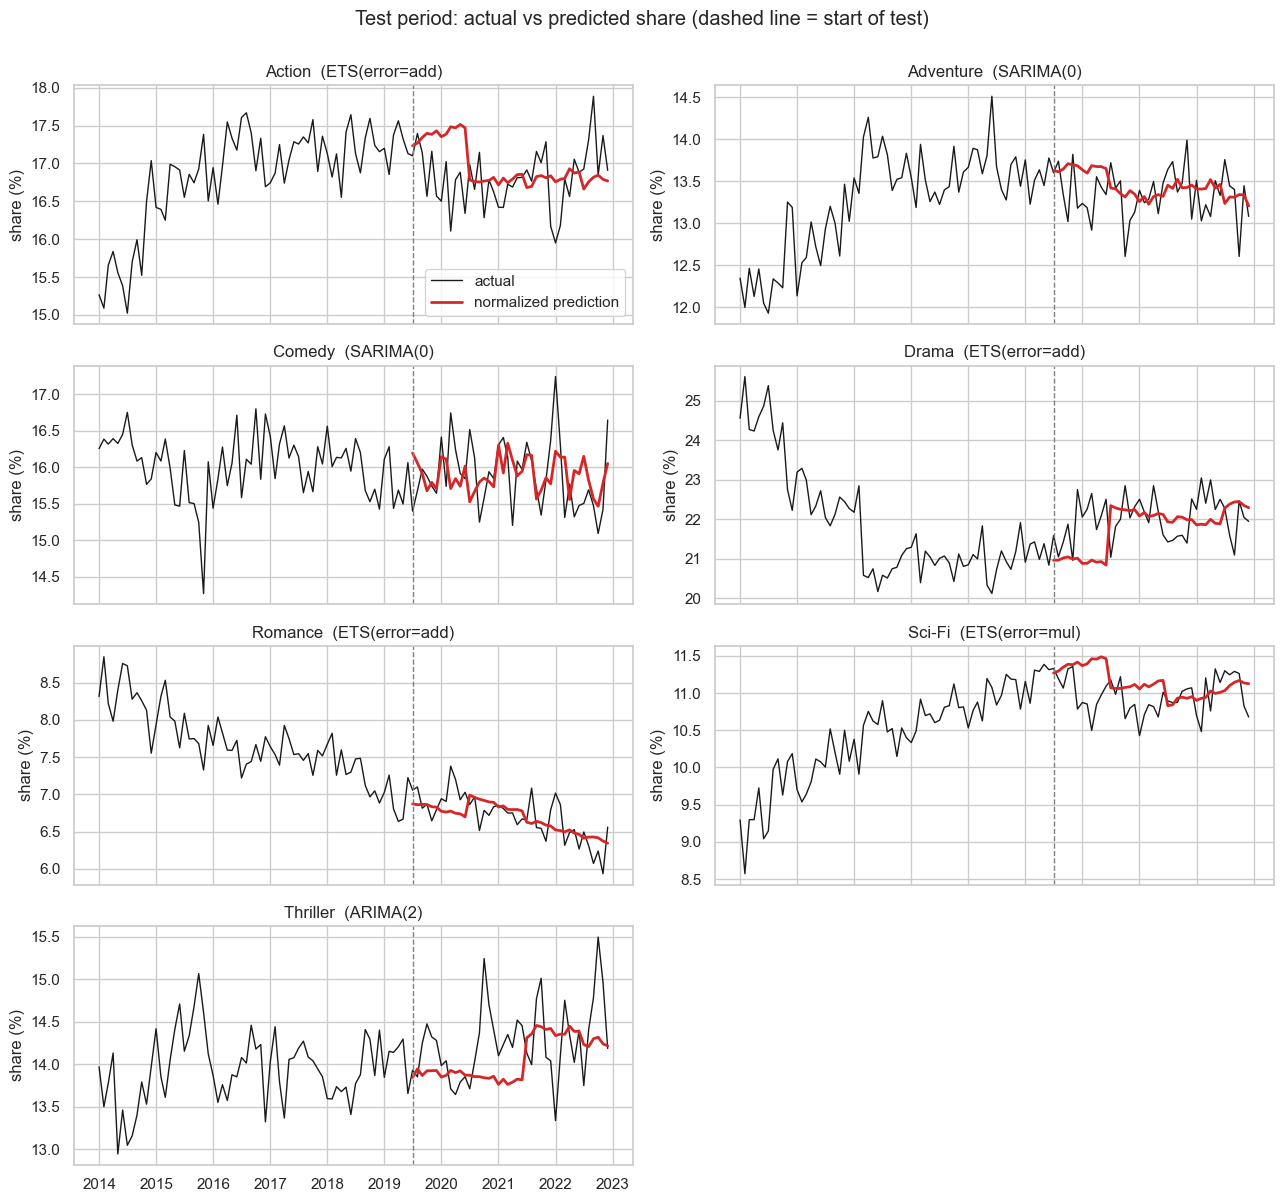

In [28]:
# Figure 1: test period, actual vs normalized prediction
fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
for ax, g in zip(axes.ravel(), GENRES):
    ax.plot(df.loc["2014":].index, df.loc["2014":, g], color="k", lw=1, label="actual")
    ax.plot(test_norm.index, test_norm[g], color="tab:red", lw=2, label="normalized prediction")
    ax.axvline(test.index[0], color="gray", ls="--", lw=1)
    ax.set_title(f"{g}  ({test_model_used[g].split(',')[0]})")
    ax.set_ylabel("share (%)")

axes.ravel()[0].legend(loc="best")
axes.ravel()[-1].axis("off")
fig.suptitle("Test period: actual vs predicted share (dashed line = start of test)", y=1.0)
plt.tight_layout()
fig.savefig(D["figures"] / "test_predictions.png", dpi=130, bbox_inches="tight")
plt.show()

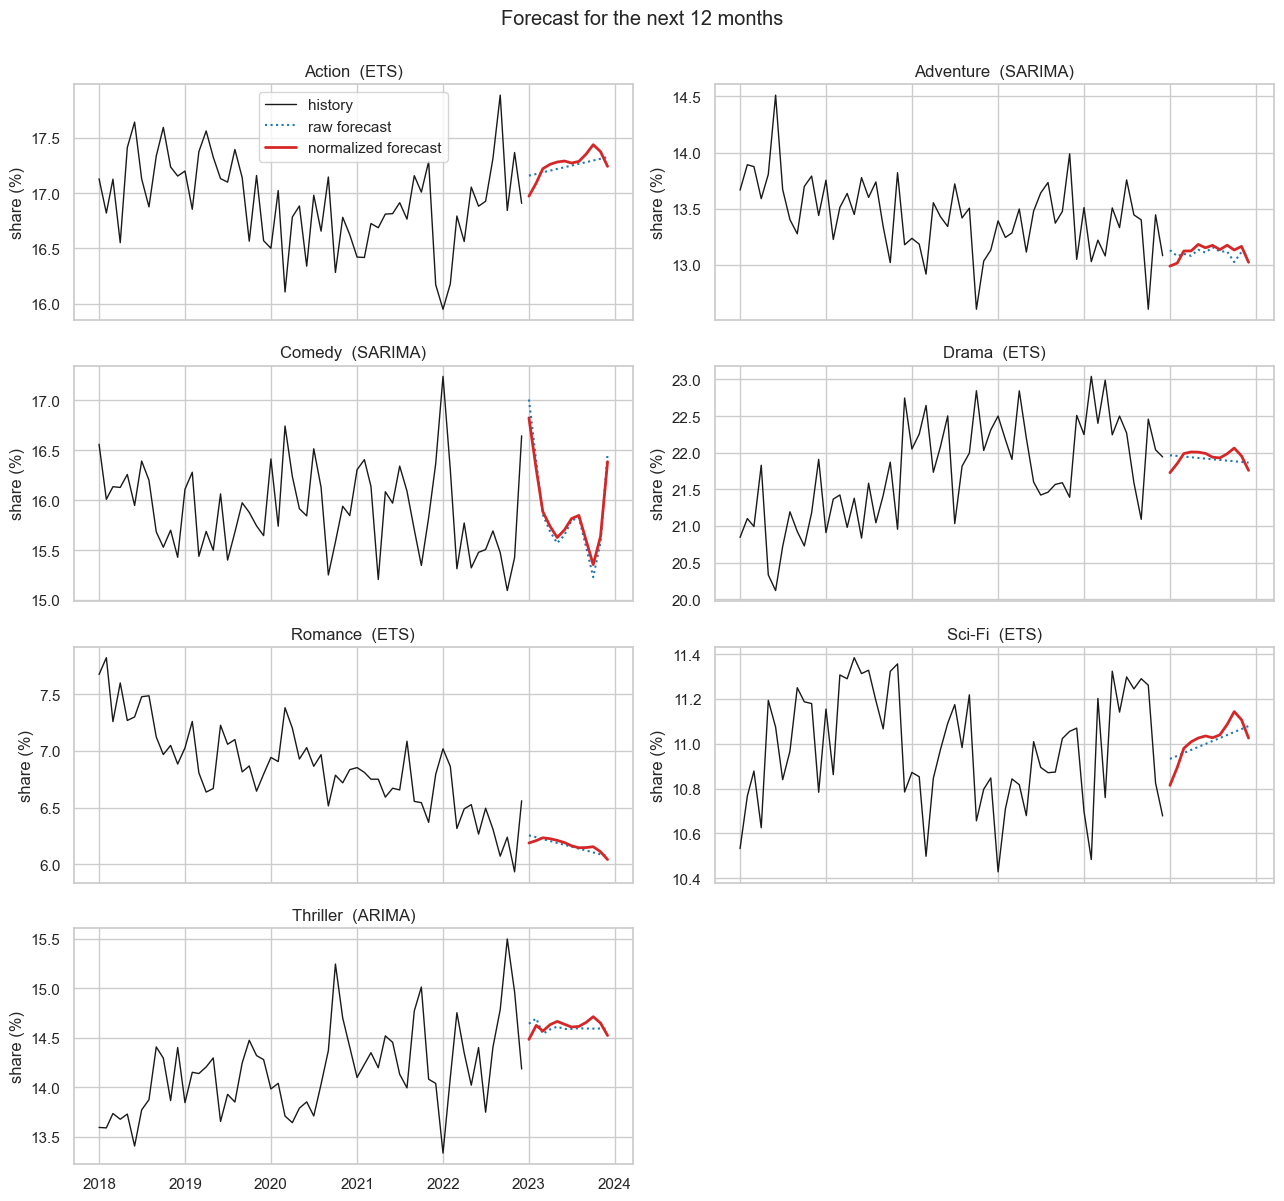

In [29]:
# Figure 2: 12-month future forecast
fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
for ax, g in zip(axes.ravel(), GENRES):
    ax.plot(df.loc["2018":].index, df.loc["2018":, g], color="k", lw=1, label="history")
    ax.plot(future_raw.index, future_raw[g], color="tab:blue", ls=":", lw=1.5, label="raw forecast")
    ax.plot(future_norm.index, future_norm[g], color="tab:red", lw=2, label="normalized forecast")
    ax.set_title(f"{g}  ({selected[g]['family']})")
    ax.set_ylabel("share (%)")
axes.ravel()[0].legend(loc="best")
axes.ravel()[-1].axis("off")
fig.suptitle("Forecast for the next 12 months", y=1.0)
plt.tight_layout()
fig.savefig(D["figures"] / "future_forecast.png", dpi=130, bbox_inches="tight")
plt.show()

## 7. Forecast interpretation

In [33]:


summary = pd.DataFrame({"historical_avg": df.mean(), "forecast_avg": future_norm.mean()})
summary["forecast_rank"] = summary["forecast_avg"].rank(ascending=False).astype(int)
summary = summary.sort_values("forecast_avg", ascending=False)

display(summary.round(2))
summary.to_csv(D["tables"] / "forecast_summary.csv")

top = summary.index[0]
print(f"Highest projected average share: {top} ({summary.loc[top, 'forecast_avg']:.1f}%)")


,historical_avg,forecast_avg,forecast_rank
Drama,22.61,21.93,1
Action,15.46,17.26,2
Comedy,17.94,15.89,3
Thriller,13.83,14.61,4
Adventure,12.17,13.12,5
Sci-Fi,9.27,11.02,6
Romance,8.72,6.17,7


Highest projected average share: Drama (21.9%)


**Reading the results.** We can see the highest popularity share though not actual popularity share but we can call as proxy or key indicator of popularity is this, which is `highest for Drama Genre`.